In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import HillClimbSearch, BIC, BDeu, K2, AIC, BDs, BayesianEstimator, ExpectationMaximization
from pgmpy.estimators.MLE import MaximumLikelihoodEstimator
from pgmpy.inference import VariableElimination
import networkx as nx
import copy
import logging
import pickle

# Suppress all pgmpy INFO messages
logging.getLogger("pgmpy").setLevel(logging.WARNING)

C:\Users\Andrej\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In this notebook, we proceed with the preprocessed dataset obtained in preprocess.ipynb, where we do exploratory data analysis, drop redundant features and discretize the numerical features for better simplicity in modeling, particularly to ensure sparse conditional probability distributions. After this process, we consider the following features:

- Hours per day (of listening to music) -> discretized into 4 bins
- While working -> binary
- Instrumentalist -> binary
- Composer -> binary
- Fav genre -> categorical
- Exploratory (whether a respondent is frequently switching genres listened to) -> binary
- BPM (of music listened) -> discretized into 4 bins
- Anxiety (self-reported) -> discretized into 4 bins
- Depression (self-reported) -> discretized into 4 bins
- Insomnia (self-reported) -> discretized into 4 bins
- OCD (self-reported) -> discretized into 2 bins
<!-- 
We proceed with using these features to manually build several Bayesian networks, explained in further detail below, as well as infer a network from the data, comparing them through various metrics, interpreting them and drawing conclusions. We then use the optimal network for analyzing its properties and performing inference. -->

In [2]:
df = pd.read_csv('datasets/mxmh_clean.csv')

In [24]:
df.head()

,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,BPM,Anxiety,Depression,Insomnia,OCD
0,2,Yes,Yes,Yes,Latin,Yes,2,1,0,0,0
1,1,Yes,No,No,Rock,Yes,1,2,1,1,0
2,3,No,No,No,Video game music,No,2,2,2,3,0
3,2,Yes,No,Yes,Jazz,Yes,1,3,2,1,0
4,3,Yes,No,No,R&B,Yes,1,2,1,2,1


In [25]:
df.describe()

,Hours per day,BPM,Anxiety,Depression,Insomnia,OCD
count,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000
mean,1.752053,1.467980,1.927750,1.610837,1.238095,0.315271
std,1.161017,0.561403,0.936136,0.994035,1.053250,0.465006
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
50%,2.000000,1.000000,2.000000,2.000000,1.000000,0.000000
75%,3.000000,2.000000,3.000000,2.000000,2.000000,1.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,1.000000


In this work we wish to study the relationship between music taste and forms of internalizing psychopathology (also refered to as "internalization"). As discussed in [1](https://d1wqtxts1xzle7.cloudfront.net/104996401/2012_Miranda_et_al_music-libre.pdf?1692026389=&response-content-disposition=inline%3B+filename%3DMusic_Listening_and_Mental_Health_Variat.pdf&Expires=1763219013&Signature=Xss8qvIdpW6yCI0o141-ej4wbJh~Vs7lVLgAEYGwb6UavPb01bERXl9q-bMl21hhSoFz5HEDjVzZLKQmXomgNu87o1Ky80VqUqciw5e5a~qdRcG8j0WqZvZ8GVN76Z5~OORbcQxRgstbvZ7ih~iGF2vgZ6VO7ycGlZC~GCXx5f0TwmBh5Nd99ayh0PS7~aefTTuSy2mcRcze3UP7jO~9Ked9y~BfVhpjfNP0jQfxkqnGvJIUPYeACYTs1hwc8YNwRmwz7lhfS-r~bMT64GjOuwvdwBNK2Ru7cZO2o8oYbvtm0uwJvKN9LAISjFJwgYaC9u8QKrOaY69N-mgydeyq-w__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) internalizing psychopathology relates several different psychopathologies (including the ones we study but also phobia, suicidal ideation, etc.) and opposes them dimensionally to externalizing psychopathology (e.g. aggression, antisocial behaviour) on the basis of correlations, which themselves indicate underlying biopshychosocial factors.

[1](https://d1wqtxts1xzle7.cloudfront.net/104996401/2012_Miranda_et_al_music-libre.pdf?1692026389=&response-content-disposition=inline%3B+filename%3DMusic_Listening_and_Mental_Health_Variat.pdf&Expires=1763219013&Signature=Xss8qvIdpW6yCI0o141-ej4wbJh~Vs7lVLgAEYGwb6UavPb01bERXl9q-bMl21hhSoFz5HEDjVzZLKQmXomgNu87o1Ky80VqUqciw5e5a~qdRcG8j0WqZvZ8GVN76Z5~OORbcQxRgstbvZ7ih~iGF2vgZ6VO7ycGlZC~GCXx5f0TwmBh5Nd99ayh0PS7~aefTTuSy2mcRcze3UP7jO~9Ked9y~BfVhpjfNP0jQfxkqnGvJIUPYeACYTs1hwc8YNwRmwz7lhfS-r~bMT64GjOuwvdwBNK2Ru7cZO2o8oYbvtm0uwJvKN9LAISjFJwgYaC9u8QKrOaY69N-mgydeyq-w__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) draws on conclusions from (Sloboda, 2010)(TODO) and (Lewinsohn, Solomon, Seeley, & Zeiss, 2000)(TODO) to form a hypothesis based on emotion regulation and gradual development, which implies that music listening might have a small, gradual and cumulative influence on menthal health. The authors of [1](https://d1wqtxts1xzle7.cloudfront.net/104996401/2012_Miranda_et_al_music-libre.pdf?1692026389=&response-content-disposition=inline%3B+filename%3DMusic_Listening_and_Mental_Health_Variat.pdf&Expires=1763219013&Signature=Xss8qvIdpW6yCI0o141-ej4wbJh~Vs7lVLgAEYGwb6UavPb01bERXl9q-bMl21hhSoFz5HEDjVzZLKQmXomgNu87o1Ky80VqUqciw5e5a~qdRcG8j0WqZvZ8GVN76Z5~OORbcQxRgstbvZ7ih~iGF2vgZ6VO7ycGlZC~GCXx5f0TwmBh5Nd99ayh0PS7~aefTTuSy2mcRcze3UP7jO~9Ked9y~BfVhpjfNP0jQfxkqnGvJIUPYeACYTs1hwc8YNwRmwz7lhfS-r~bMT64GjOuwvdwBNK2Ru7cZO2o8oYbvtm0uwJvKN9LAISjFJwgYaC9u8QKrOaY69N-mgydeyq-w__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) also list possible reasons for this influence: "Our conceptual framework argues that everyday music listening may have influences on
internalizing psychopathology because: (a) music can involve emotion regulation and coping; (b)
songs may have social cognitive influences; (c) music can have psychotherapeutic effects. "
<!-- TODO: add more concrete citation for Sloboda and Zeiss maybe after deciding which parts of the text should be moved to paper-->
   

[1](https://d1wqtxts1xzle7.cloudfront.net/104996401/2012_Miranda_et_al_music-libre.pdf?1692026389=&response-content-disposition=inline%3B+filename%3DMusic_Listening_and_Mental_Health_Variat.pdf&Expires=1763219013&Signature=Xss8qvIdpW6yCI0o141-ej4wbJh~Vs7lVLgAEYGwb6UavPb01bERXl9q-bMl21hhSoFz5HEDjVzZLKQmXomgNu87o1Ky80VqUqciw5e5a~qdRcG8j0WqZvZ8GVN76Z5~OORbcQxRgstbvZ7ih~iGF2vgZ6VO7ycGlZC~GCXx5f0TwmBh5Nd99ayh0PS7~aefTTuSy2mcRcze3UP7jO~9Ked9y~BfVhpjfNP0jQfxkqnGvJIUPYeACYTs1hwc8YNwRmwz7lhfS-r~bMT64GjOuwvdwBNK2Ru7cZO2o8oYbvtm0uwJvKN9LAISjFJwgYaC9u8QKrOaY69N-mgydeyq-w__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) goes on to conduct a review of the literature and study the possible mechanisms of such an influence, proposing research designs for establishing them. Ultimately, however this work concludes that empirical studies on the subject are few and difficult to draw conclusions from.

A futher analysis of the literature relating to music preference and mental health in adolescents is presented in [2](https://d1wqtxts1xzle7.cloudfront.net/81945163/Can_20Music_20Preference_20Indicate_20Mental_20Health_20Status_20in_20Young_20People-libre.pdf?1646848490=&response-content-disposition=inline%3B+filename%3DCan_Music_Preference_Indicate_Mental_Hea.pdf&Expires=1763215966&Signature=ZrBga8iQWJxGBwzJgYMjQ62-LPrehdl4GLD3l14JQQP7koZy6H09Cjr3Z~QRe3H4H-iqn07qBHrn60lE5aO369TfSPgVo~OsUZbP-vhO7NjbPAhWchz5BqWsoWHYObbPOqiddqVGyGUjmPrf03yUwPYrG5UbOXOfKRFC7JDFhL~UM584QLnoKAUxSDJFl~ZXFGlwW50zachruFEp39zme45Laa-a4vvWSWMAPE8x8fI2dE~zL5yJswC8M~KJK6rEaTdiFUELvi24lkIdyXJSEXyZUBCVDH8lbee4lFOydOM6vDwEIXJBJOI2olE25uLR3u25WFq7VLe5KJntrQS20A__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA). Interestingly, here the authors conclude from their review that a more likely connection between the two phenomena is that music taste might influenced by emotional factors. 

Inspired by [1](https://d1wqtxts1xzle7.cloudfront.net/104996401/2012_Miranda_et_al_music-libre.pdf?1692026389=&response-content-disposition=inline%3B+filename%3DMusic_Listening_and_Mental_Health_Variat.pdf&Expires=1763219013&Signature=Xss8qvIdpW6yCI0o141-ej4wbJh~Vs7lVLgAEYGwb6UavPb01bERXl9q-bMl21hhSoFz5HEDjVzZLKQmXomgNu87o1Ky80VqUqciw5e5a~qdRcG8j0WqZvZ8GVN76Z5~OORbcQxRgstbvZ7ih~iGF2vgZ6VO7ycGlZC~GCXx5f0TwmBh5Nd99ayh0PS7~aefTTuSy2mcRcze3UP7jO~9Ked9y~BfVhpjfNP0jQfxkqnGvJIUPYeACYTs1hwc8YNwRmwz7lhfS-r~bMT64GjOuwvdwBNK2Ru7cZO2o8oYbvtm0uwJvKN9LAISjFJwgYaC9u8QKrOaY69N-mgydeyq-w__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA)  and [2](https://d1wqtxts1xzle7.cloudfront.net/81945163/Can_20Music_20Preference_20Indicate_20Mental_20Health_20Status_20in_20Young_20People-libre.pdf?1646848490=&response-content-disposition=inline%3B+filename%3DCan_Music_Preference_Indicate_Mental_Hea.pdf&Expires=1763215966&Signature=ZrBga8iQWJxGBwzJgYMjQ62-LPrehdl4GLD3l14JQQP7koZy6H09Cjr3Z~QRe3H4H-iqn07qBHrn60lE5aO369TfSPgVo~OsUZbP-vhO7NjbPAhWchz5BqWsoWHYObbPOqiddqVGyGUjmPrf03yUwPYrG5UbOXOfKRFC7JDFhL~UM584QLnoKAUxSDJFl~ZXFGlwW50zachruFEp39zme45Laa-a4vvWSWMAPE8x8fI2dE~zL5yJswC8M~KJK6rEaTdiFUELvi24lkIdyXJSEXyZUBCVDH8lbee4lFOydOM6vDwEIXJBJOI2olE25uLR3u25WFq7VLe5KJntrQS20A__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) we aim to use the Bayesian networks to study the two hypotheses "Music taste influences internalization" and "Internalization influences music taste". For this puspose we follow the principal of causal discovery using score funcions and use the dataset "Music & Mental Health Survey", uploaded to Kaggel by Catherine Rasgaitis 

Our use of variables such as "Composer", "Exploratory", "Hours per day", "While working" gives further context to the behaviours of music listening besides the subjects' preference, which [1](https://d1wqtxts1xzle7.cloudfront.net/104996401/2012_Miranda_et_al_music-libre.pdf?1692026389=&response-content-disposition=inline%3B+filename%3DMusic_Listening_and_Mental_Health_Variat.pdf&Expires=1763219013&Signature=Xss8qvIdpW6yCI0o141-ej4wbJh~Vs7lVLgAEYGwb6UavPb01bERXl9q-bMl21hhSoFz5HEDjVzZLKQmXomgNu87o1Ky80VqUqciw5e5a~qdRcG8j0WqZvZ8GVN76Z5~OORbcQxRgstbvZ7ih~iGF2vgZ6VO7ycGlZC~GCXx5f0TwmBh5Nd99ayh0PS7~aefTTuSy2mcRcze3UP7jO~9Ked9y~BfVhpjfNP0jQfxkqnGvJIUPYeACYTs1hwc8YNwRmwz7lhfS-r~bMT64GjOuwvdwBNK2Ru7cZO2o8oYbvtm0uwJvKN9LAISjFJwgYaC9u8QKrOaY69N-mgydeyq-w__&Key-Pair-Id=APKAJLOHF5GGSLRBV4ZA) expresses as important and sometimes lacking in existing research.

We model different Bayesian networks manually (Mental health influences taste vs. taste influences influences health) for each assumption. Both networks share a set of edges that are unrelated to the causal direction dilemma, represented in personal_causes and genre_causes. Otherwise, the causal relations between genres (and features related to genres, such as BPM) and the conditions (Anxiety, Depression, Insomnia, OCD) are mirrored.

In addition, in the TIMH case, we consider the possibility of a latent variable: namely, the above mentioned internalization dimention used in psychology. Thus, a case where taste influences internalization, which in turn influences specific conditions, was also built. The causal chain of internalization -> specific conditions -> genre preferences is not considered, because it does not simplify the graph and does not have an effect of the CPDs.
<!-- TODO: get some more information on latent variables and decide if we should consider also the other direction -->

Our interest is to use causal discovery with score functions in order to see what the data from the above mentioned database says about these hypotheses by comparing said Bayesian networks. We expand our reasoning beyond the simple use of the dataset by also considering priors on the distributions of the mental illnesses present in our data. Finally, we use a Hill-Climbing approach to obtain a structure of a Bayesian network obtained from the data and compare it the those manually defined by us.

<!-- Finally, after we build all three networks as discrete Bayesian networks, we also visualize them with NetworkX. -->

In [3]:
personal_causes = [
    ('Instrumentalist', 'Composer'),
    ('Instrumentalist', 'Hours per day'),
    ('Instrumentalist', 'Fav genre'),
    ('Composer', 'Hours per day'),
    ('Composer', 'Fav genre'),
    ('While working', 'Hours per day'),
]

genre_causes = [
    ('Fav genre', 'BPM')
]

mental_health_influences_taste = [
    ('Anxiety', 'Fav genre'),
    ('Anxiety', 'BPM'),
    ('Anxiety', 'Hours per day'),
    ('Anxiety', 'Exploratory'),
    ('Depression', 'Fav genre'),
    ('Depression', 'BPM'),
    ('Depression', 'Hours per day'),
    ('Depression', 'Exploratory'),
    ('Insomnia', 'Fav genre'),
    ('Insomnia', 'BPM'),
    ('Insomnia', 'Hours per day'),
    ('Insomnia', 'Exploratory'),
    ('OCD', 'Fav genre'),
    ('OCD', 'BPM'),
    ('OCD', 'Hours per day'),
    ('OCD', 'Exploratory')
] + personal_causes + genre_causes


taste_influences_mental_health = [
    ('Fav genre', 'Anxiety'),
    ('BPM', 'Anxiety'),
    ('Hours per day', 'Anxiety'),
    ('Exploratory', 'Anxiety'),
    ('Fav genre', 'Depression'),
    ('BPM', 'Depression'),
    ('Hours per day', 'Depression'),
    ('Exploratory', 'Depression'),
    ('Fav genre', 'Insomnia'),
    ('BPM', 'Insomnia'),
    ('Hours per day', 'Insomnia'),
    ('Exploratory', 'Insomnia'),
    ('Fav genre', 'OCD'),
    ('BPM', 'OCD'),
    ('Hours per day', 'OCD'),
    ('Exploratory', 'OCD')
] + personal_causes + genre_causes

taste_influences_mental_health_latent = [
    ('Internalization', 'Anxiety'),
    ('Internalization', 'Depression'),
    ('Internalization', 'Insomnia'),
    ('Internalization', 'OCD'),
    ('Fav genre', 'Internalization'),
    ('BPM', 'Internalization'),
    ('Hours per day', 'Internalization'),
    ('Exploratory', 'Internalization')
] + personal_causes + genre_causes

In [4]:
BN_MHIT = DiscreteBayesianNetwork(mental_health_influences_taste)
BN_TIMH = DiscreteBayesianNetwork(taste_influences_mental_health)
BN_TIMH_latent = DiscreteBayesianNetwork(taste_influences_mental_health_latent, latents= {"Internalization"})

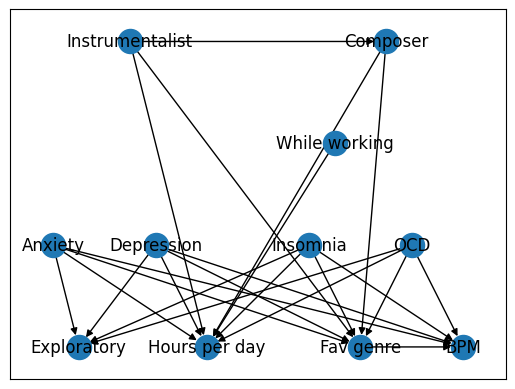

In [5]:
G = nx.DiGraph()
G.add_edges_from(BN_MHIT.edges())
pos = {'Age': [0.5, -0.5],
        'Instrumentalist': [0.25, -1],
        'Composer': [0.75, -1],
        'While working': [0.65, - 1.5],
        'Anxiety': [0.1, -2],
        'Depression': [0.3, -2],
        'Insomnia': [0.6, -2],
        'OCD': [0.8, -2],
        'Exploratory': [0.15, -2.5],
        'Hours per day': [0.4, -2.5],
        'Fav genre': [0.7, -2.5],
        'BPM': [0.9, -2.5]
}
# plt.subplots(1, 1, figsize=(12, 12))
nx.draw_networkx(G, pos=pos)


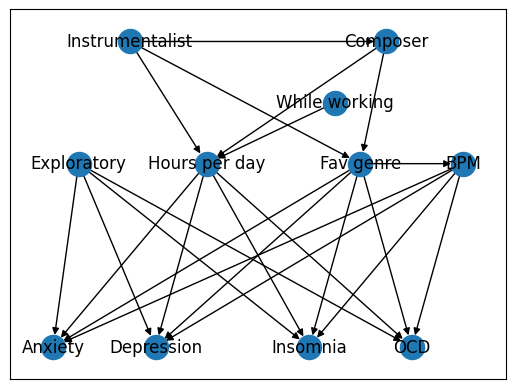

In [6]:
G = nx.DiGraph()
G.add_edges_from(BN_TIMH.edges())
pos = {'Age': [0.5, -0.5],
        'Instrumentalist': [0.25, -1],
        'Composer': [0.75, -1],
        'While working': [0.65, - 1.3],
        'Anxiety': [0.1, -2.5],
        'Depression': [0.3, -2.5],
        'Insomnia': [0.6, -2.5],
        'OCD': [0.8, -2.5],
        'Exploratory': [0.15, -1.6],
        'Hours per day': [0.4, -1.6],
        'Fav genre': [0.7, -1.6],
        'BPM': [0.9, -1.6]
}
# plt.subplots(1, 1, figsize=(12, 12))
nx.draw_networkx(G, pos = pos)

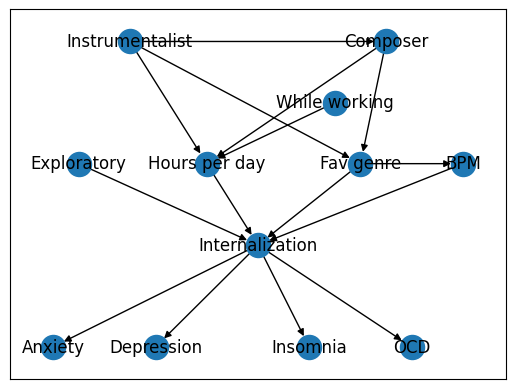

In [7]:
G = nx.DiGraph()
G.add_edges_from(BN_TIMH_latent.edges())
pos = {'Age': [0.5, -0.5],
        'Instrumentalist': [0.25, -1],
        'Composer': [0.75, -1],
        'While working': [0.65, - 1.3],
        'Anxiety': [0.1, -2.5],
        'Depression': [0.3, -2.5],
        'Insomnia': [0.6, -2.5],
        'OCD': [0.8, -2.5],
        'Internalization': [0.5, -2],
        'Exploratory': [0.15, -1.6],
        'Hours per day': [0.4, -1.6],
        'Fav genre': [0.7, -1.6],
        'BPM': [0.9, -1.6]
}
# plt.subplots(1, 1, figsize=(12, 12))
nx.draw_networkx(G, pos = pos)

We then fit estimator functions to each network in order to obtain the conditional probability distributions learned from the data. For the manually constructed networks we use a simple Maximum Likelihood Estimeation. Since the MLE works only for fully known variables, we use Expectation-Maximization with our latent network, which includes the latent variable "Internalization".

In [8]:
MHIT_copy = copy.deepcopy(BN_MHIT)
TIMH_copy = copy.deepcopy(BN_TIMH)
TIMH_latent_copy = copy.deepcopy(BN_TIMH_latent)

MHIT_estimator = MaximumLikelihoodEstimator(MHIT_copy, df)
TIMH_estimator = MaximumLikelihoodEstimator(TIMH_copy, df)
TIMH_latent_estimator = ExpectationMaximization(TIMH_latent_copy, df)

with open('pickles/MHIT_estimator.pkl', 'wb') as file:
    pickle.dump(MHIT_estimator, file)
with open('pickles/TIMH_estimator.pkl', 'wb') as file:
    pickle.dump(TIMH_estimator, file)
with open('pickles/TIMH_latent_estimator.pkl', 'wb') as file:
    pickle.dump(TIMH_latent_estimator, file)

MHIT_estimation = MHIT_estimator.get_parameters()
TIMH_estimation = TIMH_estimator.get_parameters()
TIMH_latent_estimation = TIMH_latent_estimator.get_parameters(latent_card={"Internalization": 2})

100%|██████████| 100/100 [01:54<00:00,  1.15s/it]


In [9]:
for cpd in MHIT_estimation:
    MHIT_copy.add_cpds(cpd)

for cpd in TIMH_estimation:
    TIMH_copy.add_cpds(cpd)

for cpd in TIMH_latent_estimation:
    TIMH_latent_copy.add_cpds(cpd)

Having estimated the CPDs for the above networks from our dataset, we also consider that the way in which the [dataset(TODO add source)] was collected (by an online survey) might introduce bias to the prior distributions of the variables. Indeed, this is particularly obvious with the entries for mental illnesses as seen below.


<!-- Our next interest is to consider a network where prior knowledge has been injected in order to influence the probability distributions. We consider the general prevalence rates of Anxiety, Depression, Insomnia and OCD found in the literature, and add pseudo-counts corresponding to their distributions. For simplicity, we choose the Mental Health Causes Taste network, where the four conditions have no parent nodes and thus we can introduce the priors in a simple way, making minimal assumptions about the CPDs of these conditions given other variables.

Our prior is quite strong, significantly altering the raw distributions. The scaling factor of 5 was chosen in order to balance out a weak prior vs. a prior that completely overwhelms the data, so the resulting CPDs are a middle ground. -->

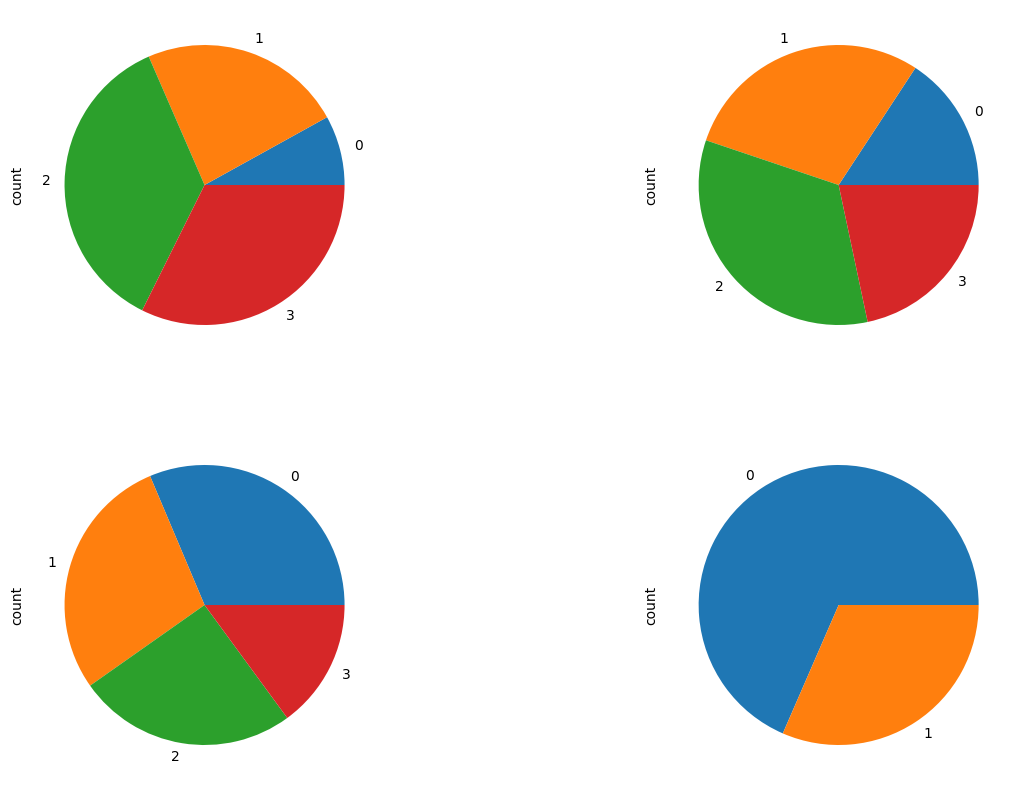

In [33]:
#TODO make subplots look better and images from mental illness papers for comparison
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()
illnesses = ["Anxiety", "Depression", "Insomnia", "OCD"]
for i, column in enumerate(illnesses):
    df[column].value_counts().sort_index().plot.pie(
        ax=axes[i]
    )

This motivates us the estimate the CPTs for another network levaraging pgmpy's Bayesian Estimator and it's ability to leverage prior distribuions. Here, we itroduce a prior as a pseudo count which helps us get closer to the distributions of the mental illnesses indicated in the aforementioned studies.

In [10]:
custom_priors = {
    "Anxiety": 100 * np.array([[84, 10, 3, 3]]).T,
    "Depression": 100 *np.array([[81, 12, 4, 3]]).T,
    "Insomnia": 100 *np.array([[82, 10, 2, 6]]).T,
    "OCD": 100 * np.array([[97, 3]]).T
}

# Create the estimator
MHIT_prior_copy = copy.deepcopy(MHIT_copy)
MHIT_prior_estimator = BayesianEstimator(MHIT_copy, df)

# Fit with custom priors (applied only to the specified variables)
for node in MHIT_prior_copy.nodes():
    if node in custom_priors:
      cpd = MHIT_prior_estimator.estimate_cpd(
          node,
          prior_type="dirichlet",
          pseudo_counts=custom_priors[node]  # only for selected variables
      )
    else:
        # Default prior for other nodes
        cpd = MHIT_prior_estimator.estimate_cpd(node, prior_type="BDeu", equivalent_sample_size=10)
    MHIT_prior_copy.add_cpds(cpd)

In [41]:
print("\n==================== COMPARING CPDs ====================\n")

for node in custom_priors.keys():
    print(f"===== {node} =====")
    
    # Original CPD
    orig_cpd = MHIT_copy.get_cpds(node)
    print("\n--- Original CPD ---")
    print(orig_cpd)
    
    # CPD with custom prior
    new_cpd = MHIT_prior_copy.get_cpds(node)
    print("\n--- CPD with Custom Prior ---")
    print(new_cpd)
    
    print("\n--------------------------------------------------------\n")


==================== COMPARING CPDs ====================

===== Anxiety =====

--- Original CPD ---
+------------+-----------+
| Anxiety(0) | 0.0804598 |
+------------+-----------+
| Anxiety(1) | 0.234811  |
+------------+-----------+
| Anxiety(2) | 0.361248  |
+------------+-----------+
| Anxiety(3) | 0.323481  |
+------------+-----------+

--- CPD with Custom Prior ---
+------------+----------+
| Anxiety(0) | 0.796399 |
+------------+----------+
| Anxiety(1) | 0.107739 |
+------------+----------+
| Anxiety(2) | 0.049015 |
+------------+----------+
| Anxiety(3) | 0.046847 |
+------------+----------+

--------------------------------------------------------

===== Depression =====

--- Original CPD ---
+---------------+----------+
| Depression(0) | 0.157635 |
+---------------+----------+
| Depression(1) | 0.29064  |
+---------------+----------+
| Depression(2) | 0.334975 |
+---------------+----------+
| Depression(3) | 0.216749 |
+---------------+----------+

--- CPD with Custom Prior

TODO add text for use of hill climbing with BIC score
<!-- We take as another consideration a structure-learned network, that is, a network where we do not provide the nodes and edges, instead, they are estimated from the data. The chosen algorithm is MMHC (Min-Max Hill Climbing), which is a two-phase structure learning algorithm:
1. Skeleton learning, during which features are connected by undirected edges in a learning process based on conditional independence tests. In this process, the graph is also pruned of all nodes that are statistically independent of all others given the data, as we see in our attempt below.
2. Hill climb search, which orients the graph according to a scoring function (in this case, BDeu).

When we draw the learned network, we observe that one of our main features of interest, Fav genre (as well as BPM) are pruned from the graph, meaning that the algorithm found the data on those features too noisy and thus could not conclude a dependence between  them and other features. This implies one of the potential risks with self-reporting surveys: the inherent bias caused by personal perceptions (particularly of mental health conditions), in contrast to medical assessments, which can introduce significant noise in the data that can make it challenging to model accurately. -->


In [ ]:
# use hill climb search to orient the edges:
hc = HillClimbSearch(df)
learned_network = hc.estimate(tabu_length=10, scoring_method=BIC(df))

with open('pickles/learned_model.pkl', 'wb') as file:
    pickle.dump(learned_network, file)
print("Part 2) Model:    ", learned_network.edges())

# Convert DAG to BayesianNetwork
learned_bn = DiscreteBayesianNetwork(learned_network.edges())

# Fit CPDs using data
learned_estimator = MaximumLikelihoodEstimator(learned_bn, df)

with open('pickles/learned_estimator.pkl', 'wb') as file:
    pickle.dump(learned_estimator, file)

cpds = learned_estimator.get_parameters()

for cpd in cpds:
    learned_bn.add_cpds(cpd)
learned_bn_copy = copy.deepcopy(learned_bn)

Part 1) Skeleton:  [('Hours per day', 'OCD'), ('Hours per day', 'Fav genre'), ('Hours per day', 'Instrumentalist'), ('Hours per day', 'BPM'), ('While working', 'Exploratory'), ('While working', 'Fav genre'), ('Instrumentalist', 'Insomnia'), ('Composer', 'Insomnia'), ('Composer', 'Depression'), ('Fav genre', 'Anxiety'), ('Fav genre', 'Depression'), ('Fav genre', 'OCD'), ('Fav genre', 'Insomnia'), ('Exploratory', 'Insomnia'), ('BPM', 'OCD'), ('BPM', 'Anxiety'), ('Anxiety', 'Insomnia')]


  0%|          | 8/1000000 [00:00<4:51:03, 57.26it/s]

Part 2) Model:     [('While working', 'Hours per day'), ('While working', 'Exploratory'), ('Composer', 'Instrumentalist'), ('Exploratory', 'Composer'), ('Anxiety', 'OCD'), ('Depression', 'Anxiety'), ('Depression', 'Insomnia'), ('OCD', 'While working')]


In [35]:
G = nx.DiGraph()
G.add_edges_from(learned_network.edges())
pos = nx.spring_layout(G)  
nx.draw(
    G, 
    pos,
    with_labels=True,
    font_size  = 8
)

NameError: name 'learned_network' is not defined

As mentioned before, we are interested in judging the fitness of the Mental Health Causes Taste assumption vs. the inverse. For this, we used two different scoring functions (BIC, BDeu), with each scoring function working according to different criteria, and the data was sampled using bootstrapping. A summary of each scoring method is given below.

## BIC (Bayesian Information Criterion)

**BIC** is a penalized log-likelihood score of the form:

$$
\phi(B \mid T) = \mathrm{LL}(B \mid T) - f(N) \cdot |B|
$$

where |B| is the number of parameters in the network and f(N) is the penalty function.

The penalty function is defined as:

$$
f(N) = \tfrac{1}{2}\log N \quad
$$

The log-likelihood of the data T given the network B is:

$$
\mathrm{LL}(B \mid T) = \sum_{i=1}^{n} \sum_{j=1}^{q_i} \sum_{k=1}^{r_i} N_{ijk} \log \frac{N_{ijk}}{N_{ij}}
$$


where:

$$
n \text{ : number of nodes in the network}
$$

$$
r_i \text{ : number of states of node } i
$$

$$
q_i \text{ : number of parent configurations of node } i
$$

$$
N_{ijk} \text{ : number of instances where node } i \text{ is in state } k \text{ and its parents are in configuration } j
$$

$$
N_{ij} = \sum_{k=1}^{r_i} N_{ijk}
$$

$$
N \text{ : sample size}
$$


---

## BDeu (Bayesian Dirichlet equivalent uniform)

BDeu is a **Bayesian score** with a uniform Dirichlet prior:

$$
\mathrm{BDeu}(B, T) = \log P(B) 
+ \sum_{i=1}^{n} \sum_{j=1}^{q_i} \Bigg[
\log \frac{\Gamma\left(\frac{\alpha}{q_i}\right)}{\Gamma\left(N_{ij} + \frac{\alpha}{q_i}\right)}
+ \sum_{k=1}^{r_i} \log \frac{\Gamma\left(N_{ijk} + \frac{\alpha}{r_i q_i}\right)}{\Gamma\left(\frac{\alpha}{r_i q_i}\right)}
\Bigg]
$$

---

## Variable Definitions

$$
n \text{ : number of nodes in the network}
$$

$$
r_i \text{ : number of states of node } i
$$

$$
q_i \text{ : number of parent configurations of node } i
$$

$$
N_{ijk} \text{ : number of instances where node } i \text{ is in state } k \text{ and its parents are in configuration } j
$$

$$
N_{ij} = \sum_{k=1}^{r_i} N_{ijk}
$$

$$
\alpha \text{ : equivalent sample size}
$$

$$
\Gamma \text{ : Gamma function}
$$

$$
P(B) \text{ : prior probability of the network structure}
$$

---

These scoring functions balance **goodness-of-fit** and **model complexity**, with BIC using penalized likelihood and BDeu incorporating Bayesian priors.


Both causal directions won one scoring test each. This can be explained through the nature of the scoring functions. Namely, the score that prefers TIMH (BIC) penalizes model complexity, and TIMH has much simpler CPDs with less parameters than MHIT, as can be seen below. Meanwhile, BDeu has no penalizing terms and focuses purely on the fit to the data. Thus, which network is better depends on the importance given to model complexity as a factor. Since we are mainly concerned with quality of fit, and can tolerate a more parameter-heavy model, we consider Mental-Health-Implies-Taste as the more likely causal direction. Still, this is a complex problem for which consensus has still not been reached, and our results may be influenced by the same risk of biased self-reporting mentioned above.

In [12]:
# Number of bootstrap resamples
n_bootstrap = 50
random_state = 42
rng = np.random.default_rng(random_state)

# Containers for bootstrap scores
bootstrap_scores = {
    'BIC':      {'MHIT': [], 'TIMH': [], 'MHIT_prior': []},
    'BDeu':     {'MHIT': [], 'TIMH': [], 'MHIT_prior': []}
}

# Perform bootstrapping
for i in range(n_bootstrap):
    sample_idx = rng.choice(df.index, size=len(df), replace=True)
    df_sample = df.iloc[sample_idx].reset_index(drop=True)

    # Compute scores for BIC
    bic = BIC(df_sample)
    bic_MHIT       = bic.score(MHIT_copy)
    bic_TIMH       = bic.score(TIMH_copy)
    bic_MHIT_prior = bic.score(MHIT_prior_copy)

    # Compute scores for BDeu
    bdeu = BDeu(df_sample)
    bdeu_MHIT       = bdeu.score(MHIT_copy)
    bdeu_TIMH       = bdeu.score(TIMH_copy)
    bdeu_MHIT_prior = bdeu.score(MHIT_prior_copy)

    # Store results
    bootstrap_scores['BIC']['MHIT'].append(bic_MHIT)
    bootstrap_scores['BIC']['TIMH'].append(bic_TIMH)
    bootstrap_scores['BIC']['MHIT_prior'].append(bic_MHIT_prior)

    bootstrap_scores['BDeu']['MHIT'].append(bdeu_MHIT)
    bootstrap_scores['BDeu']['TIMH'].append(bdeu_TIMH)
    bootstrap_scores['BDeu']['MHIT_prior'].append(bdeu_MHIT_prior)

# Compute means and standard deviations
rows = []
for score_type, values in bootstrap_scores.items():
    MHIT_mean       = np.mean(values['MHIT'])
    TIMH_mean       = np.mean(values['TIMH'])
    MHITp_mean      = np.mean(values['MHIT_prior'])

    MHIT_std        = np.std(values['MHIT'])
    TIMH_std        = np.std(values['TIMH'])
    MHITp_std       = np.std(values['MHIT_prior'])

    # Decide best model by highest mean score
    means = {
        'MHIT': MHIT_mean,
        'TIMH': TIMH_mean,
        'MHIT_prior': MHITp_mean
    }
    better = max(means, key=means.get)

    rows.append({
        'Score Type': score_type,
        'MHIT (mean)': MHIT_mean,
        'MHIT (std)': MHIT_std,
        'TIMH (mean)': TIMH_mean,
        'TIMH (std)': TIMH_std,
        'MHIT_prior (mean)': MHITp_mean,
        'MHIT_prior (std)': MHITp_std,
        'Better Model': better
    })

# Create summary DataFrame
score_comparison = pd.DataFrame(rows)

score_comparison


,Score Type,MHIT (mean),MHIT (std),TIMH (mean),TIMH (std),MHIT_prior (mean),MHIT_prior (std),Better Model
0,BIC,-59170.344018,1123.151179,-22026.337870,627.159050,-59170.344018,1123.151179,TIMH
1,BDeu,-7781.849533,78.349633,-7976.568509,89.541185,-7781.849533,78.349633,MHIT


In [14]:
def get_cpd_complexity(model):
    """
    Returns:
      total_params: total number of free parameters in the network
      detail: dict with parameter count per node
    """
    total_params = 0
    detail = {}

    for cpd in model.get_cpds():
        node = cpd.variable
        node_card = cpd.variable_card

        parent_cards = [model.get_cardinality(parent) for parent in cpd.variables[1:]]
        parent_configurations = 1
        for c in parent_cards:
            parent_configurations *= c

        # Free parameters per CPD:
        params = (node_card - 1) * parent_configurations

        detail[node] = params
        total_params += params

    return total_params, detail

In [15]:
MHIT_total, MHIT_detail = get_cpd_complexity(MHIT_copy)
TIMH_total, TIMH_detail = get_cpd_complexity(TIMH_copy)

print("===== TOTAL MODEL DIMENSIONS =====")
print(f"MHIT total parameters : {MHIT_total}")
print(f"TIMH total parameters : {TIMH_total}")

print("\n===== PER-NODE PARAMETER COUNTS =====")
print("\n--- MHIT ---")
for node, params in MHIT_detail.items():
    print(f"{node}: {params}")

print("\n--- TIMH ---")
for node, params in TIMH_detail.items():
    print(f"{node}: {params}")

===== TOTAL MODEL DIMENSIONS =====
MHIT total parameters : 17038
TIMH total parameters : 5257

===== PER-NODE PARAMETER COUNTS =====

--- MHIT ---
Anxiety: 3
Fav genre: 7680
BPM: 6144
Hours per day: 3072
Exploratory: 128
Depression: 3
Insomnia: 3
OCD: 1
Instrumentalist: 1
Composer: 2
While working: 1

--- TIMH ---
Fav genre: 60
Anxiety: 1536
BPM: 48
Hours per day: 24
Exploratory: 1
Depression: 1536
Insomnia: 1536
OCD: 512
Instrumentalist: 1
Composer: 2
While working: 1


As a final consideration, we take the comparison of bootstrapped Log-Likelihood between some of the networks that were constructed. There is an important limitation to this approach, which is that it cannot take into account features unseen in the original data. This penalizes the latent model in particular. It's not surprising that the best-performing network by log-likelihood is the one learned with MMHC, since it's learned directly from the statistical properties of the data and is free from assumptions that can introduce bias. It's also not surprising that the latent and prior models hurt the scoring with this approach, since those assumptions move the CPDs away from the observed data. 

Interestingly, however, MHIT once again performs better than TIMH, strongly suggesting that its initial loss in the scoring function comparison was caused by its higher complexity.

In [ ]:
def compare_multiple_networks_bootstrap_ll(df, models, n_bootstrap=50, random_state=42):
    """
    Compare multiple Bayesian networks using bootstrapped log-likelihood.

    Parameters
    ----------
    df : pd.DataFrame
        Observed dataset with categorical columns (strings or integers)
    models : list of tuples
        List of (name, BayesianNetwork) to compare. Each network must have CPDs attached.
        Example: [('MHIT', MHIT_copy), ('MHIT_latent', MHIT_latent_copy), ('Learned', learned_network)]
    n_bootstrap : int
        Number of bootstrap resamples
    random_state : int
        Random seed

    Returns
    -------
    pd.DataFrame
        Summary table with mean, std log-likelihood per model and which model is better
    """
    rng = np.random.default_rng(random_state)

    # Helper function to compute log-likelihood for one network
    def log_likelihood(model, df_sample):
        ll = 0
        inf = VariableElimination(model)
        observed_vars = [v for v in df_sample.columns if v in model.nodes()]

        for _, row in df_sample.iterrows():
            prob = 1.0
            for var in observed_vars:
                parents = list(model.get_parents(var))
                evidence = {p: row[p] for p in parents if p in observed_vars}

                q = inf.query([var], evidence=evidence, show_progress=False)
                cpd = model.get_cpds(var)

                # Map row value to CPD index
                if cpd.state_names:
                    val_idx = cpd.state_names[var].index(row[var])
                else:
                    val_idx = int(row[var])

                prob *= q.values[val_idx]

            ll += np.log(prob + 1e-12)  # small epsilon to avoid log(0)
        return ll

    # Initialize container for log-likelihoods
    logliks = {name: [] for name, _ in models}

    # Bootstrapping loop
    for i in range(n_bootstrap):
        sample_idx = rng.choice(df.index, size=len(df), replace=True)
        df_sample = df.iloc[sample_idx].reset_index(drop=True)

        for name, model in models:
            ll = log_likelihood(model, df_sample)
            logliks[name].append(ll)

    # Compute summary statistics
    rows = []
    for model_name, scores in logliks.items():
        rows.append({
            'Model': model_name,
            'Mean LogLik': np.mean(scores),
            'Std LogLik': np.std(scores)
        })

    summary_df = pd.DataFrame(rows)
    summary_df['Better Model'] = summary_df['Mean LogLik'] == summary_df['Mean LogLik'].max()

    pd.set_option('display.float_format', lambda x: f"{x:,.3f}")
    return summary_df

In [ ]:
models = [
    ('MHIT', MHIT_copy),
    ('TIMH', TIMH_copy),
    (' TIMH (Latent)', TIMH_latent_copy),
    ('MHIT (Prior)', MHIT_prior_copy),
    ('Learned', learned_bn_copy)
]

compare_multiple_networks_bootstrap_ll(df, models, n_bootstrap=20)

,Model,Mean LogLik,Std LogLik,Better Model
0,MHCT,"-5,189.865",25.419,False
1,TCMH,"-5,723.733",42.430,False
2,TCMH (Latent),"-6,698.688",30.991,False
3,MHCT (Prior),"-5,598.662",34.095,False
4,Learned,"-4,666.385",28.958,True


In [ ]:
for cpd in MHIT_copy.get_cpds():
    print(cpd)

+------------+-----------+
| Anxiety(0) | 0.0818404 |
+------------+-----------+
| Anxiety(1) | 0.234935  |
+------------+-----------+
| Anxiety(2) | 0.360342  |
+------------+-----------+
| Anxiety(3) | 0.322883  |
+------------+-----------+
+-----------------------------+-----+-----------------------+
| Anxiety                     | ... | Anxiety(3)            |
+-----------------------------+-----+-----------------------+
| Composer                    | ... | Composer(Yes)         |
+-----------------------------+-----+-----------------------+
| Depression                  | ... | Depression(3)         |
+-----------------------------+-----+-----------------------+
| Insomnia                    | ... | Insomnia(3)           |
+-----------------------------+-----+-----------------------+
| Instrumentalist             | ... | Instrumentalist(Yes)  |
+-----------------------------+-----+-----------------------+
| OCD                         | ... | OCD(1)                |
+------------

In [ ]:
for cpd in TIMH_copy.get_cpds():
    print(cpd)

+-----------------------------+-----+-----------------------+
| Composer                    | ... | Composer(Yes)         |
+-----------------------------+-----+-----------------------+
| Instrumentalist             | ... | Instrumentalist(Yes)  |
+-----------------------------+-----+-----------------------+
| Fav genre(Classical)        | ... | 0.11037234042553191   |
+-----------------------------+-----+-----------------------+
| Fav genre(Country)          | ... | 0.037424012158054715  |
+-----------------------------+-----+-----------------------+
| Fav genre(EDM)              | ... | 0.037424012158054715  |
+-----------------------------+-----+-----------------------+
| Fav genre(Folk)             | ... | 0.02526595744680851   |
+-----------------------------+-----+-----------------------+
| Fav genre(Gospel)           | ... | 0.01310790273556231   |
+-----------------------------+-----+-----------------------+
| Fav genre(Hip hop)          | ... | 0.04958206686930091   |
+-------

In [ ]:
for cpd in TIMH_latent_copy.get_cpds():
    print(cpd)

+------------------+-----+----------------------+
| Composer         | ... | Composer(Yes)        |
+------------------+-----+----------------------+
| Instrumentalist  | ... | Instrumentalist(Yes) |
+------------------+-----+----------------------+
| While working    | ... | While working(Yes)   |
+------------------+-----+----------------------+
| Hours per day(0) | ... | 0.07042253521126761  |
+------------------+-----+----------------------+
| Hours per day(1) | ... | 0.19718309859154928  |
+------------------+-----+----------------------+
| Hours per day(2) | ... | 0.22535211267605634  |
+------------------+-----+----------------------+
| Hours per day(3) | ... | 0.5070422535211268   |
+------------------+-----+----------------------+
+-----------------------------+-----+----------------------+
| Composer                    | ... | Composer(Yes)        |
+-----------------------------+-----+----------------------+
| Instrumentalist             | ... | Instrumentalist(Yes) |
+-----

In [ ]:
for cpd in MHIT_prior_copy.get_cpds():
    print(cpd)

+------------+----------+
| Anxiety(0) | 0.422904 |
+------------+----------+
| Anxiety(1) | 0.174031 |
+------------+----------+
| Anxiety(2) | 0.211903 |
+------------+----------+
| Anxiety(3) | 0.191163 |
+------------+----------+
+-----------------------------+-----+------------------------+
| Anxiety                     | ... | Anxiety(3)             |
+-----------------------------+-----+------------------------+
| Composer                    | ... | Composer(Yes)          |
+-----------------------------+-----+------------------------+
| Depression                  | ... | Depression(3)          |
+-----------------------------+-----+------------------------+
| Insomnia                    | ... | Insomnia(3)            |
+-----------------------------+-----+------------------------+
| Instrumentalist             | ... | Instrumentalist(Yes)   |
+-----------------------------+-----+------------------------+
| OCD                         | ... | OCD(1)                 |
+---------

In [35]:
for cpd in learned_bn_copy.get_cpds():
    print(cpd)

+--------------------+---------------------+---------------------+
| OCD                | OCD(0)              | OCD(1)              |
+--------------------+---------------------+---------------------+
| While working(No)  | 0.23182359952324194 | 0.15552699228791775 |
+--------------------+---------------------+---------------------+
| While working(Yes) | 0.7681764004767581  | 0.8444730077120822  |
+--------------------+---------------------+---------------------+
+------------------+---------------------+---------------------+
| While working    | While working(No)   | While working(Yes)  |
+------------------+---------------------+---------------------+
| Hours per day(0) | 0.48333333333333334 | 0.12050359712230216 |
+------------------+---------------------+---------------------+
| Hours per day(1) | 0.26372549019607844 | 0.2356115107913669  |
+------------------+---------------------+---------------------+
| Hours per day(2) | 0.13823529411764707 | 0.19039054470709146 |
+----------